# Qiskit Fall Fest 2026 - Workshop

# 0. Overview <a id="overview"></a>

The main goal of this notebook is to introduce key Qiskit concepts through simple, hands-on examples. As we work through the notebook step by step, participants are encouraged to ask questions along the way.

# Table of Contents

* [Overview](#overview)
* [Setting up Qiskit](#setup)
* [Building circuits](#build)
* [Running circuits](#run)
* [Analysing results](#analyse)
* [QML example](#example)

# 1. Setting up Qiskit <a id="setup"></a>

This is the installation commands use for this notebook. In case of problems, please refer to the [Qiskit installation guide](https://docs.quantum.ibm.com/guides/install-qiskit) if using venv.

In [1]:
# %pip install qiskit
# %pip install 'qiskit[visualization]'
# %pip install qiskit-ibm-runtime
# %pip install qiskit-aer
# %pip install qiskit_machine_learning
# %pip install qiskit_algorithms
# %pip install pylatexenc
# %pip install scitkit-learn

## Imports

Here are the required modules to import for the notebook.

In [5]:
from qiskit import QuantumCircuit, generate_preset_pass_manager
from qiskit.circuit import Parameter
from qiskit.circuit.library import (z_feature_map, zz_feature_map,
                                    pauli_feature_map, n_local)
from qiskit.quantum_info import Statevector
from qiskit.visualization import (plot_bloch_multivector, plot_state_qsphere,
                                  plot_histogram)
from qiskit.quantum_info import SparsePauliOp
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator, Aer
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime.fake_provider import FakeQuebec
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.circuit.library import qnn_circuit
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.optimizers import COBYLA, SPSA
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split

from utils import *

SEED = 8398

ModuleNotFoundError: No module named 'qiskit_ibm_runtime'

Check that the `utils` import works.

In [584]:
test_function()

Exercises ready!


Check your Qiskit version, you should have a Qiskit version `>=2.0.0`

In [585]:
# CHECK QISKIT VERSION
import qiskit
qiskit.__version__

'2.6.2'

# 2. Building circuits <a id="build"></a>

Now, let's look at quantum circuits, which are sequences of quantum gates.

A useful tool for playing with quantum circuits is the IBM [Circuit Composer](https://quantum.cloud.ibm.com/composer).

Here are a few popular quantum gates.

## Quantum gates

### X Gate

An X gate is the quantum equivalent of the NOT gate in classical computing (bit-flip). It maps the state $|0\rangle$ to the state $|1\rangle$ and $|1\rangle$ to $|0\rangle$, so it is equivalent to a rotation around the X-axis of the Bloch sphere by $\pi$ radians. The matrix representation is:

$X = \begin{pmatrix}
0 & 1 \\
1 & 0 \\
\end{pmatrix}$

Here is how to implement it.

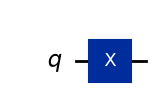

In [588]:
# Create a new circuit with one qubit
qc = QuantumCircuit(1)
# Add an X gate to the circuit
qc.x(0)
qc.draw(output='mpl')

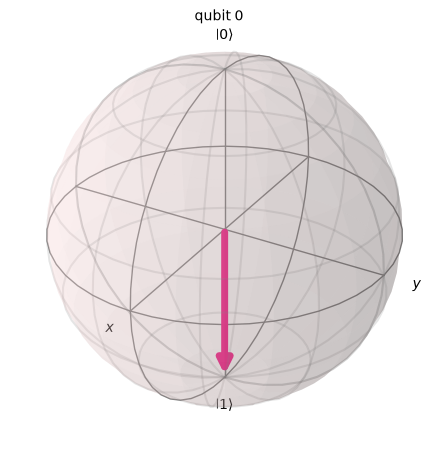

In [589]:
# On the Bloch sphere, this gives us:
sv = Statevector(qc)
plot_bloch_multivector(sv)

In [590]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

### H Gate

A Hadamard gate has no equivalent in classical computing, as it creates a *superposition* of states. For instance, it maps the basis state $|0\rangle$ to $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$, which means that we have equal probabilities of measuring `0` or `1`. This gate represents a rotation of $\pi$ about the axis that is in the middle of the $X$-axis and $Z$-axis. The matrix representation is:

$H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1 \\
\end{pmatrix}$

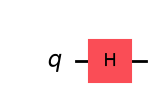

In [598]:
# Create a new circuit with one qubit
qc = QuantumCircuit(1)
# qc.x(0) # we can try on the |1> state as well by uncommenting this line.
qc.h(0)
qc.draw(output='mpl')

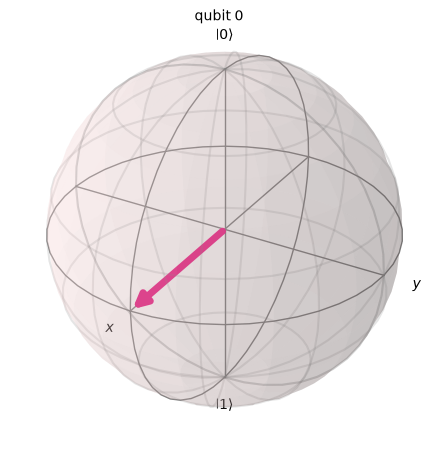

In [599]:
# On the Bloch sphere, this gives us:
sv = Statevector(qc)
plot_bloch_multivector(sv)

In [600]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

### Z Gate

A Z gate has no effect of the state $|0\rangle$, but introduces a $-1$ factor when applied to the state $|1\rangle$. It is equivalent to a phase flip, or a $\pi$ radian rotation about the $Z$-axis. The matrix representation is:

$Z = \begin{pmatrix}
1 & 0 \\
0 & -1 \\
\end{pmatrix}$

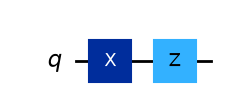

In [605]:
# Create a new circuit with one qubit
qc = QuantumCircuit(1)
qc.x(0) # we can try on the |0> state as well by commenting out this line.
qc.z(0)
qc.draw(output='mpl')

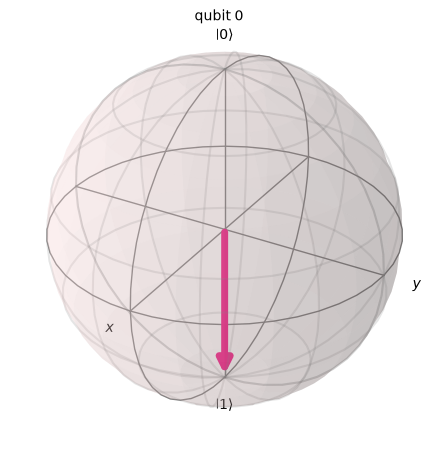

In [606]:
# On the Bloch sphere, this gives us:
sv = Statevector(qc)
plot_bloch_multivector(sv)

In [607]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

### Other single-qubit gates

Many other single-qubit gates exist, such as the Y gate, and more generally, the rotation gates RX, RY and RZ, which apply a given angle rotation about a their respective axis.

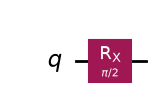

In [608]:
# Example of a rotation around the X-axis by π/2 radians.
# Create a new circuit with one qubit
qc = QuantumCircuit(1)
qc.rx(np.pi/2, 0)
qc.draw(output='mpl')

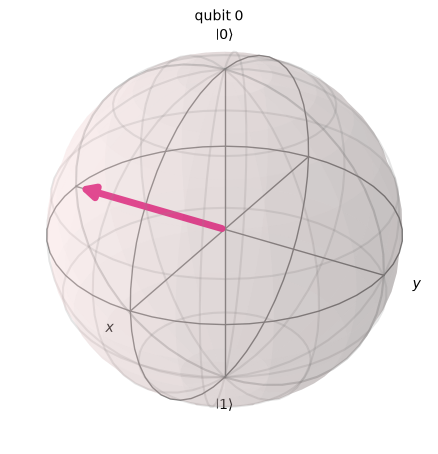

In [609]:
# On the Bloch sphere, this gives us:
sv = Statevector(qc)
plot_bloch_multivector(sv)

In [610]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

### CX Gate

The CX gate, or CNOT gate, is a controlled NOT gate acting on **two qubits**. It applies the NOT operation (X gate) on the second qubit only if the first qubit is in state $|1\rangle$, otherwise it leaves it as is. The matrix representation is:

$CX = \begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0\\
\end{pmatrix}$

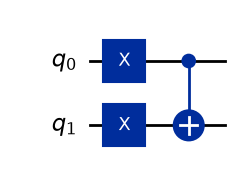

In [612]:
# Create a new circuit with two qubits
qc = QuantumCircuit(2)
qc.x(0)
qc.x(1)
qc.cx(0, 1)
qc.draw(output='mpl')

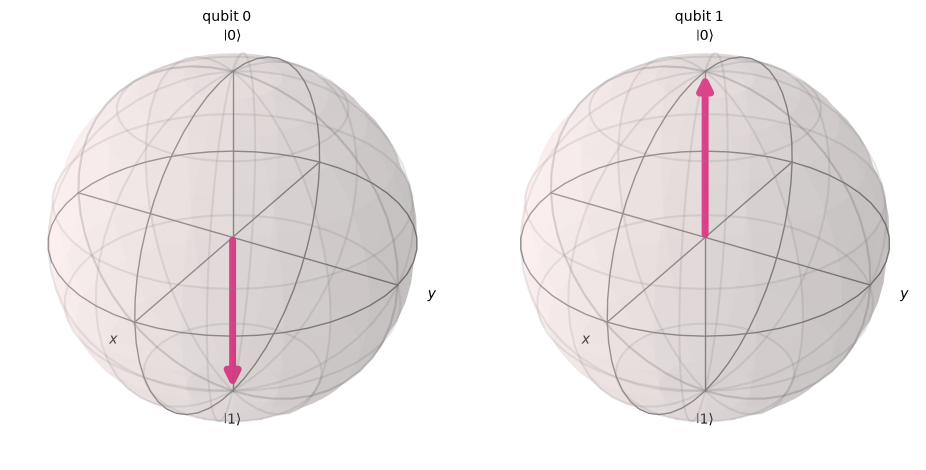

In [613]:
# On the Bloch sphere, this gives us:
sv = Statevector(qc)
plot_bloch_multivector(sv)

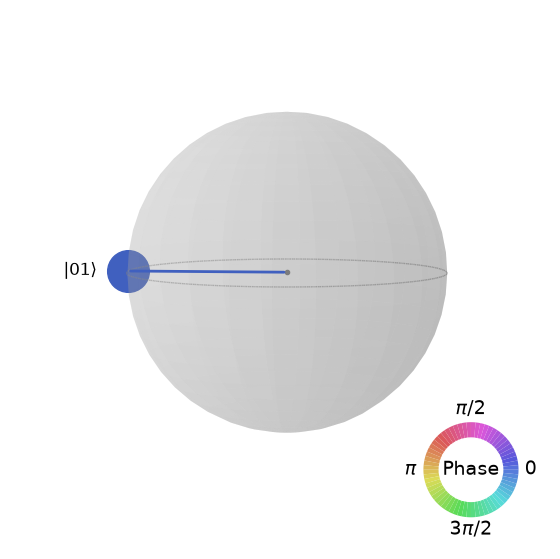

In [614]:
# On the q-sphere, this gives us:
plot_state_qsphere(sv)

In [615]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

**IMPORTANT**: We see here that Qiskit numbers the bits in a string from RIGHT TO LEFT, meaning that the first qubit is the rightmost one, the second is the second from the right, and so on.

## Bell states (entanglement)

Combined with the Hadamard gate, the CNOT gate allows us to create entanglement between the two qubits. Let's see how it works.

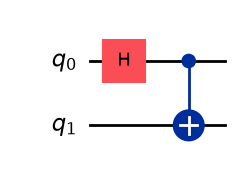

In [616]:
# Create a new circuit with two qubits
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.draw(output='mpl')

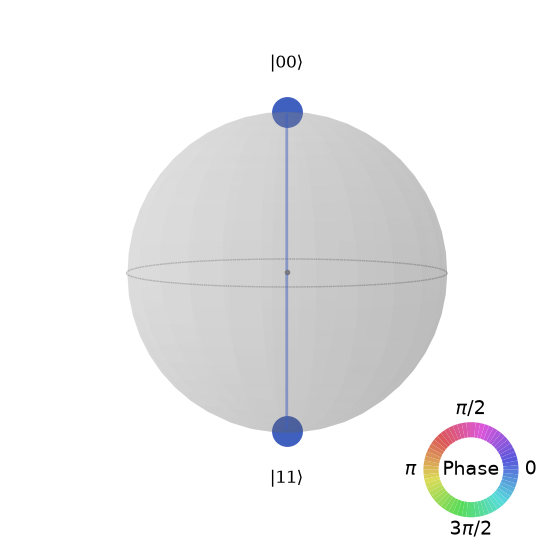

In [617]:
# On the q-sphere, this gives us:
sv = Statevector(qc)
plot_state_qsphere(sv)

In [618]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

This circuit creates a state called a Bell state. When we measure the qubits, we can only find the states $|00\rangle$ and $|11\rangle$, which means that both qubits *must* have the same value. If we measure only one qubit, we *know* for sure that the other one is also in the same state without even having to measure it. This is a very important feature of quantum mechanics and it leads to powerful quantum algorithms.

Let's create another Bell state.

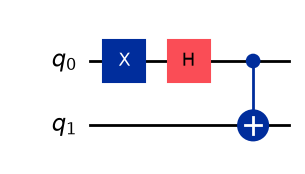

In [619]:
# Create a new circuit with two qubits
qc = QuantumCircuit(2)
qc.x(0)
qc.h(0)
qc.cx(0,1)
qc.draw(output='mpl')

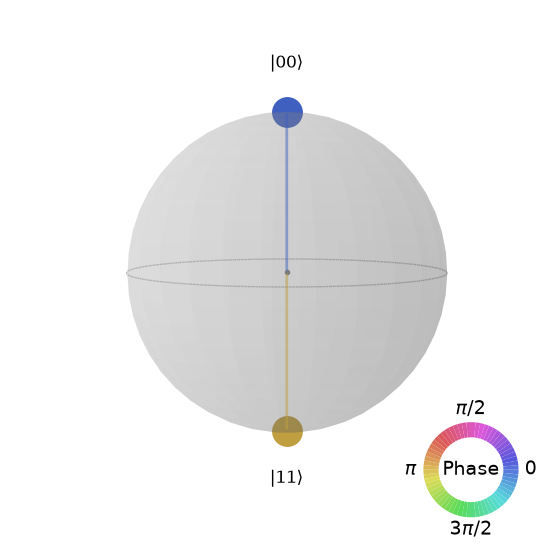

In [620]:
# On the q-sphere, this gives us:
sv = Statevector(qc)
plot_state_qsphere(sv)

In [621]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

We can now re-create the Qiskit logo state!

$$ |Qiskit \rangle = \frac{1}{\sqrt 2}(|0010 \rangle + |1101 \rangle) $$

![qiskit_logo](Figures/qiskit_logo.png)

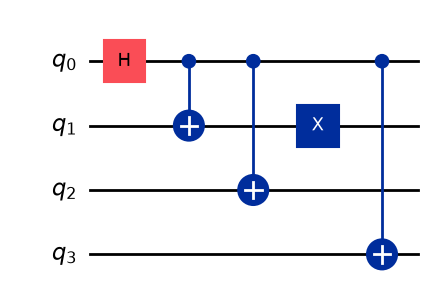

In [622]:
# Create a new circuit with four qubits
qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0,1)
qc.cx(0,2)
qc.cx(0,3)
qc.x(1)
qc.draw("mpl")

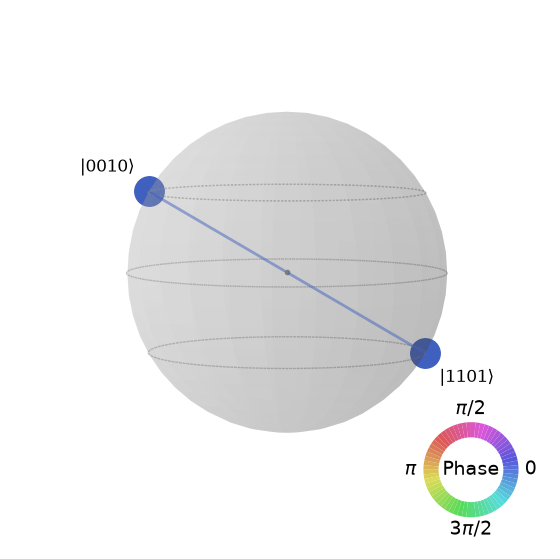

In [623]:
# On the q-sphere, this gives us:
sv = Statevector(qc)
plot_state_qsphere(sv)

In [624]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

# 3. Running circuits

Now that we know how to build basic circuits, we could explore more useful circuits for solving interesting problems! But first, let's take a step back and understand what can be done with a given circuit and how it can be run on a quantum computer.

Let's start with a circuit creating the famous Greenberger-Horne-Zeilinger (GHZ) state, an extension of the Bell state where three qubits are maximally entangled:

$$
|GHZ\rangle = \frac{|000\rangle+|111\rangle}{\sqrt{2}}.
$$

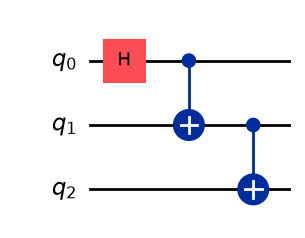

In [625]:
# Create a new circuit with three qubits
qc = QuantumCircuit(3)
qc.h(0) 
qc.cx(0, 1)
qc.cx(1, 2)
qc.draw("mpl")

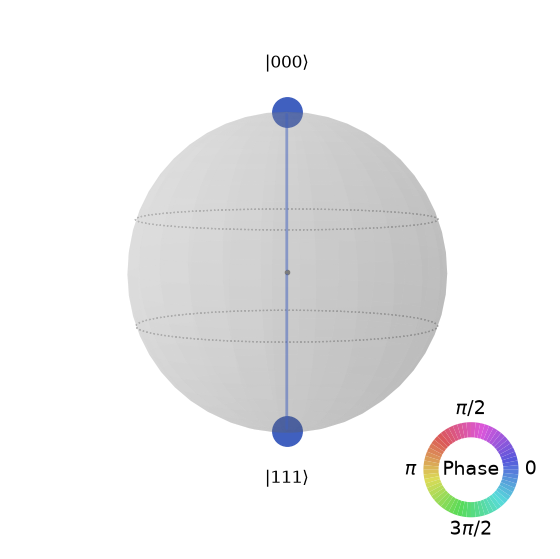

In [626]:
# On the q-sphere, this gives us:
sv = Statevector(qc)
plot_state_qsphere(sv)

In [627]:
# In the ket notation, this is represented as:
sv.draw(output='latex')

<IPython.core.display.Latex object>

## Primitives

Now, what do we want to do with this circuit? 

There are two ways of executing this circuit in Qiskit, through what they call [Primitives](https://quantum.cloud.ibm.com/docs/en/api/qiskit/primitives):

1. Use the **Estimator** to obtain the expectation value of an *observable* with respect to the state generated by the quantum circuit.
2. Use the **Sampler** to obtain a probability distribution for a set of qubits you choose to measure. This samples the output register multiple times and outputs the number of times each state was measured.

### Estimator

The expectation value of an *operator* $\hat{O}$ with respect to the state $|\psi\rangle$ generated by the quantum circuit is:

$$
\langle \hat{O}\rangle = \langle \psi |  \hat{O} | \psi \rangle
$$

In the context of our three qubit GHZ state, possible Pauli operators are `ZZZ`, `ZZX`, `ZII`, `XXI`, `ZZI`, `III`. These operators are also *observables* (real-world quantities that can be measured), because they are Hermitian. 

In general, operators can be constructed as strings of Pauli operators `X`, `Y`, `Z` and `I` to compute useful expectation values like the expected total energy of a system in the state $| \psi \rangle$, given a certain Hamiltonian $\hat{H}$ describing the system:

$$
\langle \hat{H}\rangle = \langle \psi |  \hat{H} | \psi \rangle
$$

In [628]:
# Define some observables
observables_labels = ["ZZZ", "ZZX", "ZII", "XXI", "ZZI", "III"]
observables = [SparsePauliOp(label) for label in observables_labels]
print(observables)

[SparsePauliOp(['ZZZ'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZZX'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZII'],
              coeffs=[1.+0.j]), SparsePauliOp(['XXI'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZZI'],
              coeffs=[1.+0.j]), SparsePauliOp(['III'],
              coeffs=[1.+0.j])]


What do we expect for the expectation value of these operators with respect to the GHZ state? Let's see some examples.

For the `ZZI` operator, we have:

\begin{align*}
    \langle \hat{O}\rangle &= \langle \psi |  \hat{O} | \psi \rangle\\
    & = \langle GHZ| Z\otimes Z\otimes I | GHZ\rangle\\
    & = \langle GHZ| ZZI | GHZ\rangle\\
    & = \frac{\langle000|+\langle111|}{\sqrt{2}}(ZZI)\frac{|000\rangle+|111\rangle}{\sqrt{2}}\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(ZZI|000\rangle + ZZI|111\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|000\rangle + (-1)(-1)|111\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|000\rangle+|111\rangle)\right)\\
    & = \frac{1+1}{2} = 1
\end{align*}

Equivalently, the `III` operator (identity) also gives an expectation value of 1.

For the `ZZZ` operator, we have:

\begin{align*}
    \langle \hat{O}\rangle &= \langle \psi |  \hat{O} | \psi \rangle\\
    & = \langle GHZ| ZZZ | GHZ\rangle\\
    & = \frac{\langle000|+\langle111|}{\sqrt{2}}(ZZZ)\frac{|000\rangle+|111\rangle}{\sqrt{2}}\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(ZZZ|000\rangle + ZZZ|111\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|000\rangle + (-1)(-1)(-1)|111\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|000\rangle-|111\rangle)\right)\\
    & = \frac{1-1}{2} = 0
\end{align*}

Equivalently, the `ZII` operator also gives an expectation value of 0.

For the `ZZX` operator, we have:

\begin{align*}
    \langle \hat{O}\rangle &= \langle \psi |  \hat{O} | \psi \rangle\\
    & = \langle GHZ| ZZX | GHZ\rangle\\
    & = \frac{\langle000|+\langle111|}{\sqrt{2}}(ZZX)\frac{|000\rangle+|111\rangle}{\sqrt{2}}\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(ZZX|000\rangle + ZZX|111\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|001\rangle + (-1)(-1)|110\rangle)\right)\\
    & = \frac{1}{2}\left((\langle000|+\langle111|)(|001\rangle+|110\rangle)\right)\\
    & = \frac{0}{2} = 0
\end{align*}

Equivalently, the `XXI` operator also gives an expectation value of 0.

The **Estimator** Primitive will evaluate each of these operators' expectation value with respect to the circuit built.

### Sampler

The **Sampler** Primitive samples the circuit and returns the probability distribution of measurement outcomes. For the GHZ state, this should mean the $000$ bitstring $50\%$ of the time, and $111$ bitstring $50\%$ of the time.

Note that this means we will have to add measurement gates to the circuit. We will see this later.

## Choice of backend

The next step is to choose a backend on which to run our quantum circuits. First of all, if you did not yet setup `QiskitRuntimeService` on your machine, use the commented lines below (or follow this [Documentation](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/initialize-account)). Don't forget to put your own `TOKEN` and `CRN`. 

In [ ]:
# One-time setup on your own machine:
# QiskitRuntimeService.save_account(
#     channel="ibm_quantum_platform",
#     token="PASTE_YOUR_TOKEN_HERE",
#     instance="PASTE_YOUR_CRN_HERE",
#     name="qiskit_fall_fest",
#     set_as_default=False, # Set to True if you don't want to specify the name of the account every time you use it.
#     overwrite=True,
# )

For this example, let us choose the `ibm_quebec` backend, which is the quantum computer located at IBM in Bromont, Québec.

From this, we have three main ways to continue.

Run our calculations on:
1) The **real IBM Quebec**. (This sends the job remotely to the real quantum computer.)
2) A **fake IBM Quebec**. (This runs the job locally on a simulator using a static snapshot of IBM's Quebec processor. However, this fake version is not up to date.)
3) The **AerSimulator**. (This runs the job locally on a simulator based on the backend it is given, using its current basis gates, coupling map, properties and noise model.)

Note that both simulator options (2, 3) only work for small circuits. Also, the simulator is not an exact representation of the actual quantum computer.

In [629]:
service = QiskitRuntimeService()

# Choose a real backend (1)
real_backend = service.backend("ibm_quebec")
# print backend details
print(
    f"Name: {real_backend.name}\n"
    f"Version: {real_backend.backend_version}\n"
    f"No. of qubits: {real_backend.num_qubits}\n"
    f"Processor type: {real_backend.processor_type}\n"
)

# Choose a fake backend (2)
fake_backend = FakeQuebec()
# print backend details
print(
    f"Name: {fake_backend.name}\n"
    f"Version: {fake_backend.backend_version}\n"
    f"No. of qubits: {fake_backend.num_qubits}\n"
    f"Processor type: {fake_backend.processor_type}\n"
)

# Choose a simulator backend (3)
sim_backend = AerSimulator().from_backend(real_backend, seed_simulator=SEED,
                                          method="matrix_product_state")
# print backend details
print(
    f"Name: {sim_backend.name}\n"
    f"Version: {sim_backend.backend_version}\n"
    f"No. of qubits: {sim_backend.num_qubits}\n"
)

Name: ibm_quebec
Version: 2.0.23
No. of qubits: 156
Processor type: {'family': 'Heron', 'revision': '2'}

Name: fake_quebec
Version: 1.2.143
No. of qubits: 127
Processor type: {'family': 'Eagle', 'revision': 3}

Name: aer_simulator_from(ibm_quebec)
Version: 2.0.23
No. of qubits: 156



For the remainder of the notebook, we will use `sim_backend`.

In [630]:
backend = sim_backend
print(backend)

AerSimulator('aer_simulator_from(ibm_quebec)'
             noise_model=<NoiseModel on ['reset', 'measure_reset', 'cz', 'id', 'measure_reset_2', 'xslow', 'sx', 'x', 'reset_2', 'measure', 'measure_2']>)


Note that we could also use a noiseless simulator using `sim_backend = AerSimulator()`.

## Optimization

If we want to execute our circuit on a device, it is important to optimize the set of instructions that the circuit contains (gates) and minimize the overall depth of the circuit (number of instructions that cannot be done simultaneously). This is to ensure that we obtain the best results possible by reducing the effects of error and noise. Moreover, the circuit's instructions must conform to the backend device's [Instruction Set Architecture (ISA)](https://docs.quantum.ibm.com/guides/transpile#instruction-set-architecture) and must also consider the device's basis gates and qubit connectivity.

To deal with this, we use a transpiler tool from Qiskit that transpiles the circuit into an ISA circuit. In short, the transpiler "translates" our circuit into something the backend device understands, with the gates it has access to and the qubits assigned to specific qubits on the device.

### Estimator transpilation

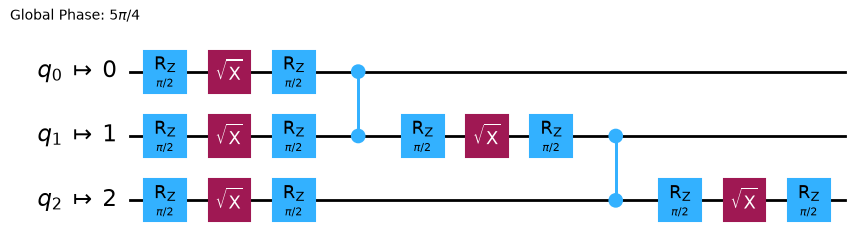

In [631]:
# Convert to an ISA circuit 
# Generate the pass manager, which is a list of transpiler passes grouped into a logical unit
pm_estimator = generate_preset_pass_manager(backend=backend, optimization_level=1) # Here, the optimization level is set to 1, but you can try other levels as well (0, 2, 3), 3 being the most aggressive optimization level.
# Run the pass manager to create the ISA circuit
isa_circuit_estimator = pm_estimator.run(qc)
# Draw the circuit, note: idle_wires = False to hide all the qubits not being used
isa_circuit_estimator.draw("mpl", idle_wires=False) 

Here, the Hadamard gate is replaced by this group of basis gates $RZ(\pi/2)\sqrt{X}RZ(\pi/2)$, while the CNOT gates are replaced by the equivalent control-Z gate sandwiched by Hadamard gates.

We also see that qubits $q_0,q_1,q_2$ are mapped to the qubits 0, 1 and 2 on the device. They could have been mapped to other connected qubits allowing for the control-Z gate.

### Sampler transpilation

For the **Sampler** Primitive, we first have to add measurement gates to the circuit, then do the transpilation.

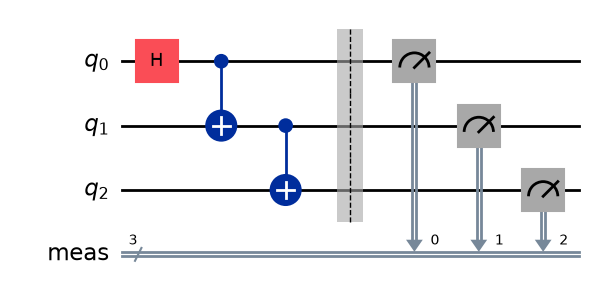

In [633]:
# Use measure_all, which adds a barrier, applies measurement gates on all qubits, creates a classical register called `meas`
qc.measure_all() 
qc.draw('mpl')

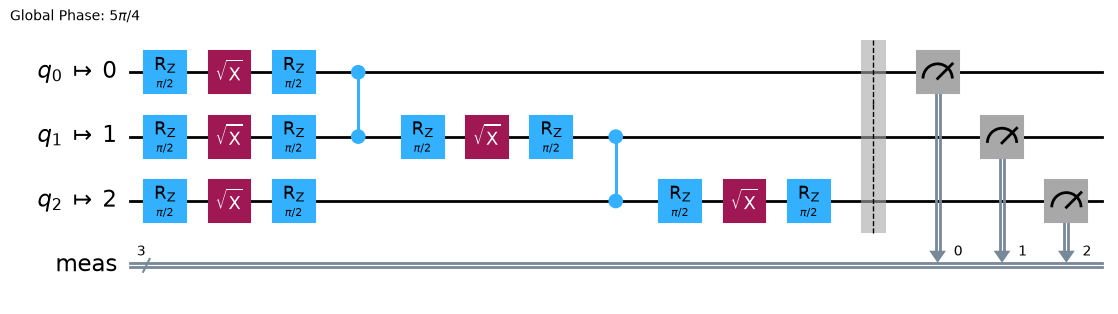

In [634]:
# Convert to an ISA circuit
pm_sampler = generate_preset_pass_manager(backend=backend, optimization_level=1) 
isa_circuit_sampler = pm_sampler.run(qc)
isa_circuit_sampler.draw("mpl", idle_wires=False) 

## Execution

We are now ready to send the ISA circuit to the device!

Usually, since a quantum computer can produce random results, we run the circuit many times to collect samples (number of shots). The `Estimator` and `Sampler` classes possess a `run()` method that executes the circuits, observables and parameters we chose for the experience, using a [primitive unified bloc (PUB)](https://docs.quantum.ibm.com/guides/primitive-input-output#pubs). Indeed, we could want to run multiple circuits with multiple observables and/or parameters. We will see later an example of such paramters.

### Estimator execution

First, we need to map the operators or observables to the qubits chosen in the ISA circuit. We see that we now have very long Pauli strings where most qubits have the identity, but the qubits affected by our circuit do have the right Pauli operators.

In [635]:
# Create layout-mapped observables for the ISA circuit
isa_observables = [
    observable.apply_layout(isa_circuit_estimator.layout) for observable in observables
]
print(isa_observables)

[SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZZ'],
              coeffs=[1.+0.j]), SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZX'],
              coeffs=[1.+0.j]), SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZII'],
              coeffs=[1.+0.j]), SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIXXI'],
              coeffs=[1.+0.j]), SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII

We are finally ready to run the circuit with **Estimator** and these observables.

In [636]:
# Creates an estimator using the selected backend
estimator = Estimator(mode=backend)

job_estimator = estimator.run([(isa_circuit_estimator, isa_observables)])
print(f">>> Job ID: {job_estimator.job_id()}")
# Result of the entire primitive execution. (You submitted one PUB, so this contains one inner result, and some metadata of its own.):
job_estimator_result = job_estimator.result()
# Result from your single PUB, which had six observables, so contains information on all six:
pub_result_estimator = job_estimator.result()

>>> Job ID: 36901db7-9791-43cb-9cb0-07786afab60f


If chosen backend was the real `ibm_quebec` device, it could have taken some time to complete. We can always retrieve a job with its job ID, using these commands: 

In [ ]:
# retrieved_job = service.job('your_job_id_here')
# retrieved_result = retrieved_job.result()

### Sampler execution

For the **Sampler**, there is no need for operators so we can directly do:

In [637]:
# Create a sampler using the selected backend
sampler = Sampler(mode=backend) 
# Here are some Sampler options for noise mitigation and error suppression
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.enable_measure = True
# sampler.options.twirling.num_randomizations = 480
# sampler.options.twirling.shots_per_randomization = 400

# Run the sampler primitive on ISA circuit for specified number of shots (1024)
job_sampler = sampler.run([isa_circuit_sampler], shots=1024) 
# Save the result of the job 
result_sampler = job_sampler.result()

# 4. Analysing results <a id="analyse"></a>

Last but not least, we need to analyse these results. Here are quick examples of how to present the results from the **Estimator** and **Sampler** runs.

## Estimator results

We see that as expected, observables $ZZI$ and $III$ have an expectation value close to 1, while the rest of the observables are near 0.

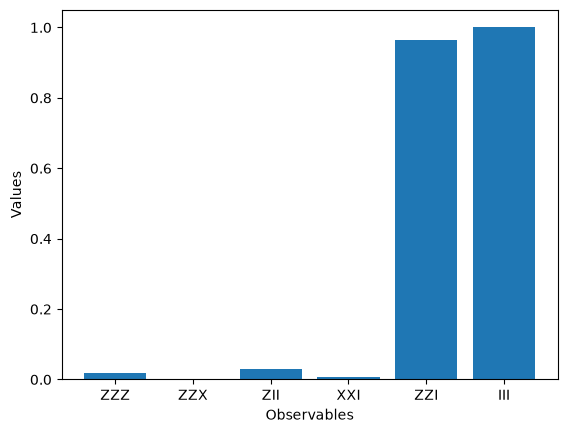

In [267]:
# Plot the result
values = pub_result_estimator[0].data.evs 
# Plot graph
container = plt.bar(observables_labels, values, width=0.8)
plt.xlabel("Observables")
plt.ylabel("Values")
plt.show()

## Sampler results

Here, we see the 50/50 probability of measuring either state $|000\rangle$ or state $|111\rangle$.

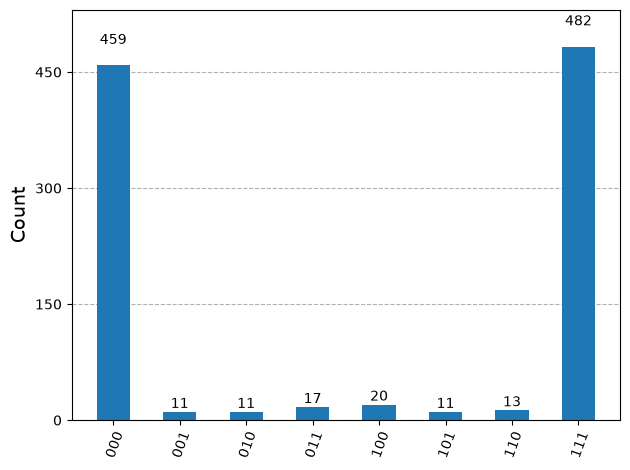

In [268]:
counts = result_sampler[0].data.meas.get_counts() 
# Note: meas is the default name of the classical register when using measure_all(). 
# If you specify a classical register, then use the name you assign

# Plot the result
plot_histogram(counts)

# 5. QML example <a id="example"></a>

Now, let's use this knowledge on a quantum machine learning (QML) example. In the following, we will explore the various steps to data classification using quantum circuits.



In [638]:
# For simplicity, we will use a noiseless statevector simulator for the following examples.
sv_backend = AerSimulator(method='statevector', seed_simulator=SEED)

## Introducing the Iris dataset

For this example, we will use the Iris dataset from scikit-learn. This dataset consists of 50 samples from each of three species of Iris (the flower). Four features were measured from each sample.

Let's see what it looks like.

In [639]:
# Load Iris dataset
# Composed of 150 samples, 3 classes, 4 features
iris = datasets.load_iris()

nb_features = 4 #Defining this variable for later

print('Feature vectors:\n', iris['data'][45:55]) #Choosing 45:55 to see elements from both classes
print('Targets:',iris['target'][45:55])

Feature vectors:
 [[4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.9 1.5]
 [5.5 2.3 4.  1.3]
 [6.5 2.8 4.6 1.5]]
Targets: [0 0 0 0 0 1 1 1 1 1]


In [640]:
# Binary classification, we only keep classes 0 and 1
nb_classes = 2
Y = iris.target[:100] 
X = np.array([x / np.linalg.norm(x) for x in iris.data[:100]]) #Normalizing the data 

for i in range(0, len(X), 15):
    print(f'Vector: {X[i]} -- label: {Y[i]}')
print(f'Dataset size: {len(X)}')

Vector: [0.80377277 0.55160877 0.22064351 0.0315205 ] -- label: 0
Vector: [0.77381111 0.59732787 0.2036345  0.05430253] -- label: 0
Vector: [0.80846584 0.52213419 0.26948861 0.03368608] -- label: 0
Vector: [0.82210585 0.51381615 0.23978087 0.05138162] -- label: 0
Vector: [0.76923077 0.30769231 0.53846154 0.15384615] -- label: 1
Vector: [0.76785726 0.34902603 0.51190484 0.16287881] -- label: 1
Vector: [0.72337118 0.34195729 0.57869695 0.15782644] -- label: 1
Dataset size: 100


In [641]:
# Split dataset in train and test sets
test_ratio = 0.2
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=test_ratio, random_state=SEED, stratify=Y)
print(f'Size of the train set: {len(x_train)}\nSize of the test set: {len(x_test)}')  

Size of the train set: 80
Size of the test set: 20


In [642]:
# Look at the first training sample
x_train[0]

array([0.776114  , 0.54974742, 0.30721179, 0.03233808])

## Data embedding

### Non-linearly separable 1D database

Let's construct a database made of points that are not linearly separable in 1D.

In [643]:
x0,x1 = get_non_seperable_data()
nb_features = 1

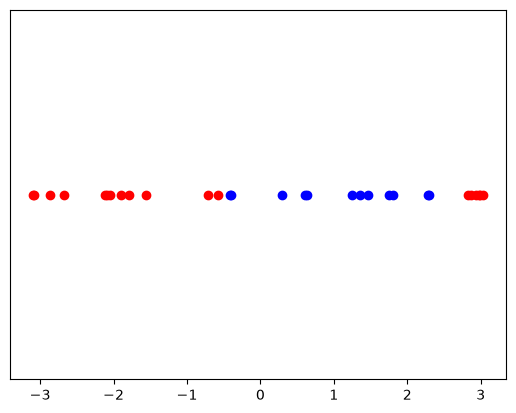

In [644]:
# Let's see what our dataset look like. Label 0 in blue, label 1 in red
plt.yticks([])
plt.scatter(x0, [0]*len(x0), color='blue')
plt.scatter(x1, [0]*len(x1), color='red')

As we can see, no straight line can separate the *blue* datapoints from the *red* ones.

We say that the data is not *linearly separable*.

Let's explore the idea of data embedding and quantum feature maps to make this data seperable in a different space!

### Data embedding

We can embed classical data into quantum states by using a **quantum feature map** $\phi(\mathbf{x})$. The data is then in a new higher dimensional space. Different feature maps exist, and we will see a few below.

 As always, the qubits are initialized in the zero state $|0\rangle$. The first layer of circuits in QML will be this data embedding layer.

#### Angle embedding

We need to define a parametrized circuit. Its parameters will be used to load the data in the quantum circuit.

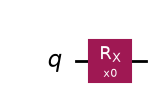

In [645]:
# Create a list of `Parameter`. Since the data points have only one feature
# there will be only one parameter in this list.
x_params = [Parameter(f'x{str(i)}') for i in range(nb_features)]

# Instanciate a quantum circuit
qc = QuantumCircuit(nb_features)

for i in range(nb_features):
    # Data encoding using the rotation RX
    qc.rx(x_params[i], i)

qc.draw('mpl')

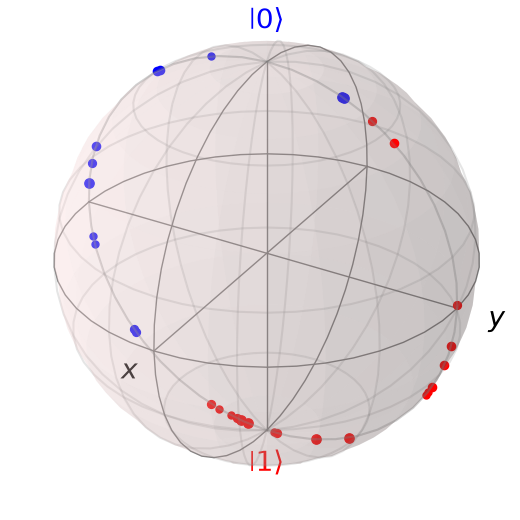

In [646]:
# Tell the simulator to save the statevector at the end of the circuit
qc.save_statevector()
# Obtain the state vector corresponding to each points in the dataset
statevectors0 = get_statevector(qc, x0, x_params, sv_backend)
statevectors1 = get_statevector(qc, x1, x_params, sv_backend)

# Visualization of the dataset on the Bloch sphere
plot_bloch_visualization([statevectors0, statevectors1], ['b', 'r'])

#### Angle data embedding of the Iris dataset

In [647]:
x_train, y_train, x_test, y_test = get_iris(SEED)
nb_features = 4
x_train[0]

array([0.776114  , 0.54974742, 0.30721179, 0.03233808])

Let's define a function which takes in a quantum circuit and a feature vector, and embeds this feature vector with **angle embedding**.

In [648]:
def angle_embedding(qc, feature_vec):  
    
    """
    Qubit - or rotation - encoding in RX gates.

    :param qc: The quantum circuit.
    :param feature_vec: The feature vector parametrizing the RX gates.
                        The number of qubit in the circuit should be equal to the number
                        of feature in the input vector. 
    :return: The quantum circuit with the embedding layer. 
    """
    if qc.num_qubits != len(feature_vec):
        raise ValueError('Number of features must match number of qubits')

    for i in range(qc.num_qubits):
        qc.rx(feature_vec[i], i)

    return qc
    

Let's start by embedding a single feature vector into a quantum state

Features for the first datapoint: [0.776114   0.54974742 0.30721179 0.03233808]


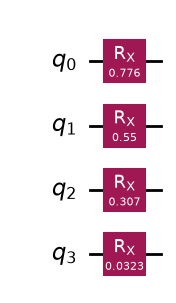

In [649]:
print('Features for the first datapoint:', x_train[0])

nb_qubits = nb_features
qc = QuantumCircuit(nb_qubits)

# Add the data embedding layer
qc = angle_embedding(qc, x_train[0])

qc.draw("mpl")

We can see that the values of the feature vector are now the angles of rotations in the $X$-axis. 

#### Amplitude embedding

Let's encode this particular state:

($\frac{1}{\sqrt{2}}$, 0, 0, $\frac{1}{\sqrt{2}}$)

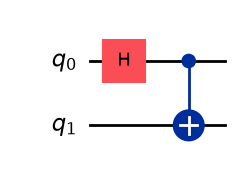

In [650]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.draw('mpl')

Notice that this circuit creates a Bell pair!

Amplitude embedding uses no specific gates, it depends on the data vector.<br>
In some cases, like the one above, creating the correct circuit is trivial.<br>
In most cases though,it is not obvious which circuit represents the quantum state in question.

Fortunately, Qiskit can help us with this! The __[raw_feature_vector class](https://stfc.github.io/qiskit-machine-learning/_modules/qiskit_machine_learning/circuit/library/raw_feature_vector)__ loads the data into qubit amplitudes automatically. Let's try it out.



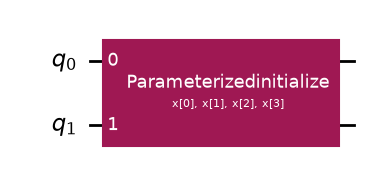

In [651]:
qc = raw_feature_vector(nb_features) 
qc.draw('mpl')

[0.776114   0.54974742 0.30721179 0.03233808]


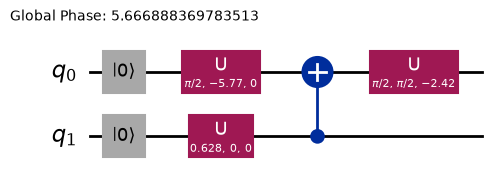

In [652]:
qc = qc.assign_parameters(x_train[0]) 
print(x_train[0])
qc.decompose().decompose().decompose().decompose().decompose().decompose().draw('mpl')

In [653]:
# The quantum circuit gives the right state!
Statevector.from_instruction(qc)

Statevector([0.776114  +0.j, 0.54974742+0.j, 0.30721179+0.j,
             0.03233808+0.j],
            dims=(2, 2))


#### Quantum feature maps with Qiskit




Qiskit also offers different feature maps: `z_feature_map`, the `zz_feature_map` and the `pauli_feature_map`. Feel free to consult this complete description of [data encoding](https://quantum.cloud.ibm.com/learning/en/courses/quantum-machine-learning/data-encoding) with Qiskit.

We can draw each of these to see what exactly they do.

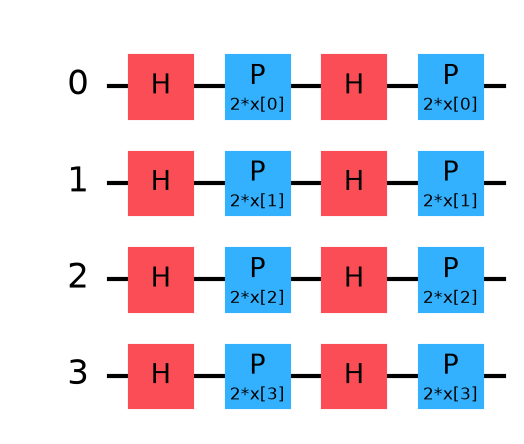

In [654]:
map_z = z_feature_map(feature_dimension=nb_features, reps = 2)
map_z.draw('mpl', scale = 1.5)

The [P gate](https://qiskit.org/documentation/stubs/qiskit.circuit.library.PhaseGate.html) is a phase gate. 

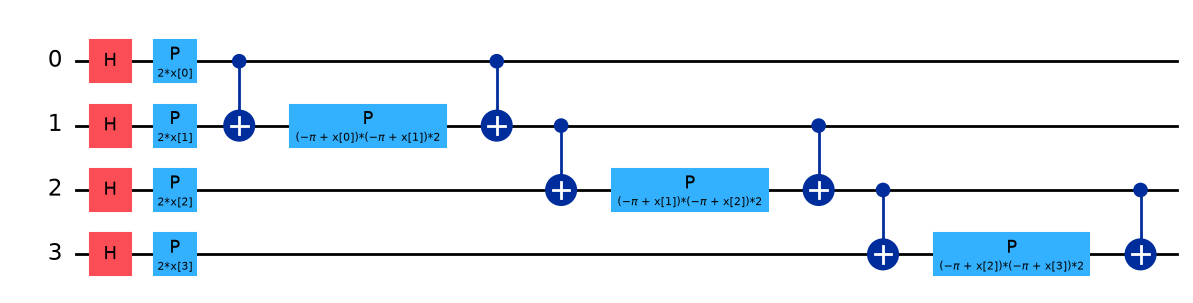

In [655]:
map_pauli = pauli_feature_map(feature_dimension=4, reps=1, entanglement = 'linear')
map_pauli.draw('mpl')

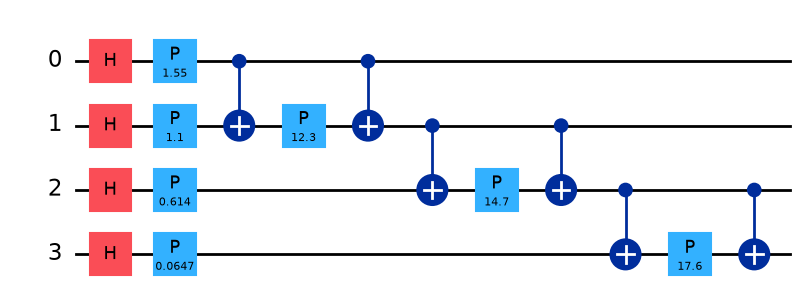

In [656]:
encode_circuit = map_pauli.assign_parameters(x_train[0])
encode_circuit.draw('mpl')

In [657]:
# The quantum circuit gives the right state!
Statevector.from_instruction(qc)

Statevector([0.776114  +0.j, 0.54974742+0.j, 0.30721179+0.j,
             0.03233808+0.j],
            dims=(2, 2))


#### Exercise: 
Embed the classical data point x = (-5, 4.5, 0.2, 1) using the `zz_feature_map`. 

In [ ]:
##Your code here##

x = None

zz_circuit = zz_feature_map()

zz_circuit.decompose().draw('mpl')

## Classification

**Objectives**
- Classify data in higher dimensional space using 1 qubit 
- Measurement along $X$,$Y$,$Z$ axis  


### 1D linearly separable dataset

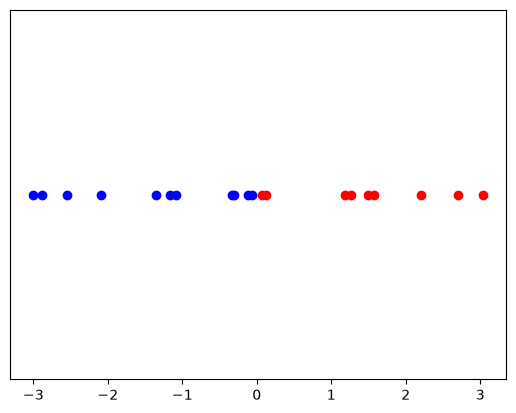

In [528]:
x,y,x0,x1 = get_seperable_data()
nb_features = 1

# Let's see what our dataset look like. Label 0 in blue, label 1 in red
plt.yticks([])
plt.scatter(x0, [0]*len(x0), color='blue')
plt.scatter(x1, [0]*len(x1), color='red')

Embedding datapoints in the rotation angle about the X-axis.

In [464]:
def angle_embedding(x_params,nb_features):
       
    """
    Qubit - or rotation - encoding in RX gates.

    :param x_params: List of parameters to embed.
    :param nb_features: The number of features of the feature vector. 
    :return: The quantum circuit with the embedding layer. 
    """
    
    qc = QuantumCircuit(nb_features)

    for i in range(nb_features):
        qc.rx(x_params[i], i)

    return qc 


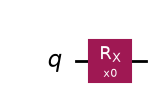

In [529]:
# Create a list of `Parameter`. Since the data points have only one feature
# there will be only one parameter in this list.
x_params = [Parameter(f'x{str(i)}') for i in range(nb_features)]

# Create the parametrized embedding layer
qc = angle_embedding(x_params, nb_features)

qc.draw('mpl')

Encoding for datapoint [-0.12203916]:


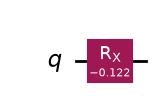

In [530]:
emb_circuit = qc.assign_parameters(x[0])

print(f'Encoding for datapoint {x[0]}:')
emb_circuit.draw('mpl')

#### Using angle embedding to map this data into a quantum feature space. 

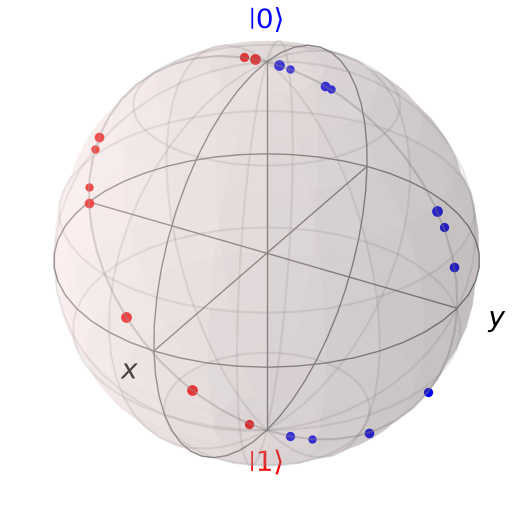

In [531]:
qc.save_statevector()
statevectors0 = get_statevector(qc, x0, x_params, sv_backend)
statevectors1 = get_statevector(qc, x1, x_params, sv_backend)
plot_bloch_visualization([statevectors0, statevectors1], ['b', 'r'])

### Implementation of the classification algorithm
![algorithm.png](Figures/algorithm.png)

In [532]:
shots = 1024


def get_measurement_outcomes(data, emb_circuit, rot_circuit=None):
    """
    Run the circuit of the binary quantum classifier for all the data vectors of a dataset.

    :param data:        Dataset to classify
    :param emb_circuit: Angle embedding circuit.
    :param rot_circuit: Circuit defining the measurement basis.
                        Defaults to the computational basis (Z)

    :return: A list of measurement results, one per data vector in the dataset.
    """
    # Add the circuit defining the measurement basis.
    if rot_circuit != None:
        emb_circuit = emb_circuit.compose(rot_circuit)

    circuits = []
    # For each datapoint in the dataset
    for x_i in data:
        x_params = emb_circuit.parameters
        # Dictionary associating one data feature to one parameter in the circuit
        x_params_dict = {p:v for (p,v) in zip(x_params, x_i)}
        # Replace the circuit parameters by their associated values
        gqc = emb_circuit.assign_parameters(x_params_dict)
        # Ajouter la mesure de tous les qubits
        # Add the measurement instruction for all qubits
        gqc.measure_all()
        circuits.append(gqc)

    # Run the circuit "N" times (determined by the number of shots)
    # Create a sampler using the selected backend
    sampler = Sampler(mode=backend) 
    # Run the sampler primitive on the circuit for specified number of shots
    job_sampler = sampler.run(circuits, shots=shots) 
    # Save the result of the job 
    result_sampler = job_sampler.result()
    counts = []
    for i in range(len(data)):
        counts.append(result_sampler[i].data.meas.get_counts())

    return counts

In [533]:
counts = get_measurement_outcomes(x, qc)
counts

[{'0': 1021, '1': 3},
 {'0': 238, '1': 786},
 {'0': 608, '1': 416},
 {'0': 1023, '1': 1},
 {'0': 1024},
 {'0': 993, '1': 31},
 {'0': 711, '1': 313},
 {'0': 575, '1': 449},
 {'0': 1020, '1': 4},
 {'0': 722, '1': 302},
 {'0': 996, '1': 28},
 {'1': 970, '0': 54},
 {'0': 671, '1': 353},
 {'0': 742, '1': 282},
 {'1': 998, '0': 26},
 {'1': 1020, '0': 4},
 {'1': 1023, '0': 1},
 {'0': 504, '1': 520},
 {'1': 940, '0': 84},
 {'1': 851, '0': 173}]

In [534]:
def get_probabilities_from_counts(counts):
    """
    Compute the probabilities of belonging to class 0 or 1 according to 
    the measurement results of a binary classifier.
    """
    num_classes = 2
    probs = []

    # For each measurement results corresponding to a datapoint in the dataset
    for dict_meas in counts:
        # We count the number of times we observed 0 and 1 respectively
        indiv_probs = np.zeros(num_classes)
        indiv_probs[0] = dict_meas.get('0', 0)
        indiv_probs[1] = dict_meas.get('1', 0)
        # We translate the number of observation instances of 0 and 1 into probabilities
        indiv_probs /= shots
        probs.append(indiv_probs)

    return np.round(probs, decimals=3)

In [535]:
probs = get_probabilities_from_counts(counts)
probs

array([[0.997, 0.003],
       [0.232, 0.768],
       [0.594, 0.406],
       [0.999, 0.001],
       [1.   , 0.   ],
       [0.97 , 0.03 ],
       [0.694, 0.306],
       [0.562, 0.438],
       [0.996, 0.004],
       [0.705, 0.295],
       [0.973, 0.027],
       [0.053, 0.947],
       [0.655, 0.345],
       [0.725, 0.275],
       [0.025, 0.975],
       [0.004, 0.996],
       [0.001, 0.999],
       [0.492, 0.508],
       [0.082, 0.918],
       [0.169, 0.831]])

In [536]:
def get_accuracy(probs, targets):
    """
    Compute the accuracy obtained by the binary classifier

    :param probs:   The probability predicted by the classifier for each data vector to be
                    in class 0 or 1.

    :param targets: List of labels.

    :return: classifier precision.
    """
    # The predicted class correponds to the one with the highest probability
    predict = np.argmax(probs, axis=1)
    targets = np.array(targets).reshape(predict.shape)
    # We count the number of times the prediction corresponds to the label and we divide
    # by the total number of predictions.
    accuracy = np.sum(predict == targets) / len(predict)
    
    return accuracy

In [537]:
accuracy = get_accuracy(probs, y)
print(f'>\n> The accuracy of our classifier is {accuracy*100}%.\n>')

>
> The accuracy of our classifier is 55.00000000000001%.
>


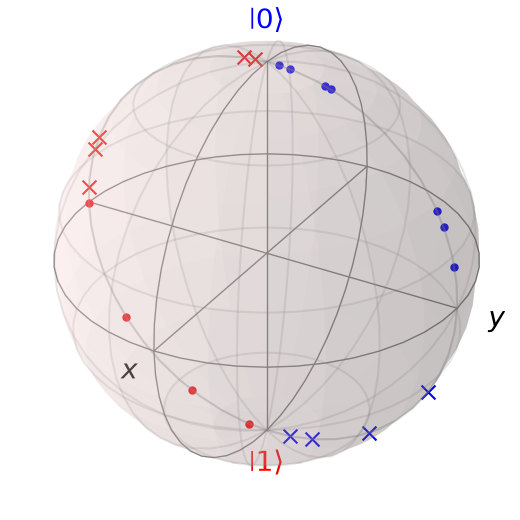

In [538]:
predict = np.argmax(probs, axis=1)
plot_bloch_visualization([statevectors0, statevectors1], x=x, x0=x0, x1=x1, score=(predict==np.array(y).reshape(predict.shape)))

The X points are those who have been misclassified.<br>
Are you surprised?<br>
How could we do better?


#### Measuring along the Y-axis

To measure along the Y-axis, we proceed by applying $|\psi'\rangle = HS^\dagger|\psi\rangle$ where the $S$ gate is a $\phi = \frac{\pi}{2}$ rotation around the Z-axis.

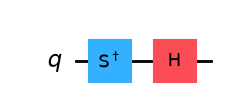

In [539]:
qc_ybasis = QuantumCircuit(1)
qc_ybasis.sdg(0)
qc_ybasis.h(0)

qc_ybasis.draw('mpl')

In [540]:
counts = get_measurement_outcomes(x, qc, qc_ybasis)
probs = get_probabilities_from_counts(counts)
accuracy = get_accuracy(probs, y)
print(f'>\n> The accuracy of our classifier is {accuracy*100}%.\n>')

>
> The accuracy of our classifier is 100.0%.
>


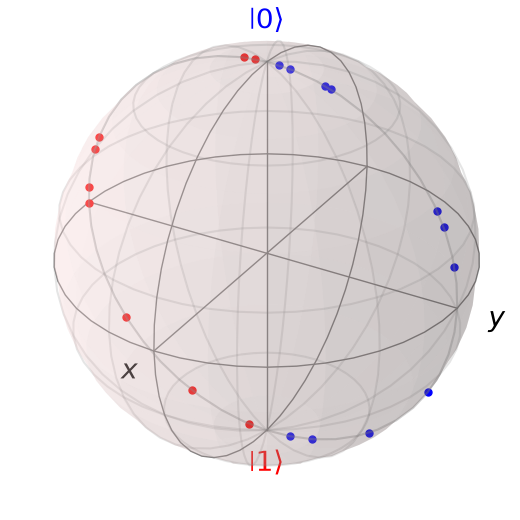

In [541]:
predict = np.argmax(probs, axis=1)
plot_bloch_visualization([statevectors0, statevectors1], x=x, x0=x0, x1=x1, score=(predict==np.array(y).reshape(predict.shape)))

#### Exercise: 
 * Implement the angle embedding such that the rotations are performed about the Y-axis.
 * Implement the quantum circuit `qc_xbasis` which performs measurements in the X basis, by simply adding a $H$ gate.<br>
 Validate your results by making sure you obtain an accuracy of 100%!

In [ ]:
def angle_embedding_ry(x_params, nb_features):
    """
    Angle embedding using RY gates.

    :param x_params: List of parameters to embed.
    :param nb_features: Number of features in a data vector.

    :return: The quantum circuit applying the angle embedding.
    """

    ## Your code here!
    qc = None

    return qc 

In [ ]:
qc = angle_embedding_ry(x_params, 1)
statevectors0 = get_statevector(qc, x0, x_params, sv_backend)
statevectors1 = get_statevector(qc, x1, x_params, sv_backend)
plot_bloch_visualization([statevectors0, statevectors1], ['b', 'r'])

In [ ]:
## Your code here!

qc_xbasis = None

qc_xbasis.draw('mpl')

In [ ]:
## Your code here!

counts = None
probs = None
accuracy = None
print(f'>\n> The accuracy of our classifier is {accuracy*100}%.\n>')

## Training a quantum classifier

**Objectives**
- Building a parametrized circuit 
- Angle embedding
- Variational quantum circuit (ansatz)  
- Classification of the Iris dataset


In [559]:
x_train, y_train, x_test, y_test = get_iris(SEED)
nb_features = 4
nb_classes = 2

### Building a quantum classifier

#### Parametrized quantum circuit

This parametrized quantum circuit is composed of two elements: 

* An embedding circuit 
* A circuit to learn the measurement basis

As always, the qubits are initialized in the zero state $|0\rangle$. The first circuit of a QML model will be the data embedding circuit. 

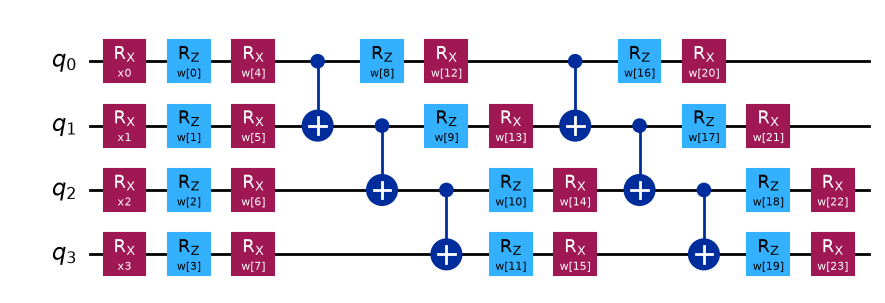

In [568]:
# Data embedding circuit
x_params = [Parameter(f'x{str(i)}') for i in range(nb_features)]    
emb_circuit = angle_embedding(x_params, nb_features)

# Circuit to learn the measurement basis
ansatz = n_local(nb_features, ['rz', 'rx'], 'cx', 'linear', reps=2, parameter_prefix='w')

qc = emb_circuit.compose(ansatz)
qc.draw('mpl')


#### Circuit QNN

In [561]:
# Random initialization of the weights
np.random.seed(SEED)
initial_weights = np.random.rand(ansatz.num_parameters) 

In [562]:
# Interpretation function: parity 
# counts the nuumber of "1" in the bit string, x,
# and returns 0 is the number is even, 1 if it is odd
def parity(x):
    return '{:b}'.format(x).count('1') % 2

In [ ]:
# Initialize the optimizer
num_iter = 20
optimizer = COBYLA(maxiter=num_iter)

# !!! Let's use the original noisy backend here !!!
sampler = Sampler(mode=backend)
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.enable_measure = True
# sampler.options.twirling.num_randomizations = 100
# sampler.options.twirling.shots_per_randomization = 100

sampler_qnn = SamplerQNN(circuit=qc,
                         sampler=sampler,
                         input_params=emb_circuit.parameters,
                         weight_params=ansatz.parameters, 
                         interpret=parity, 
                         output_shape=nb_classes)

In [576]:
# The probability to be classified as belonging to class 0 or 1 for a given datapoint,
# and a given parameter value, are obtained with the function `CircuitQNN.forward()`
probs = sampler_qnn.forward(x_train[0], initial_weights)
print(f">\n> Probability to belong in class 0: {probs[0][0]*100:.1f}%\n> Probability to belong in class 1: {probs[0][1]*100:.1f}%\n>")

>
> Probability to belong in class 0: 59.9%
> Probability to belong in class 1: 40.1%
>


### Training of the classifier with `Neural Network Classifier`

In [577]:
# Instantiate a `NeuralNetworkClassifier` to train our model and make inferences
circuit_classifier = NeuralNetworkClassifier(neural_network=sampler_qnn,
                                             optimizer=optimizer,
                                             initial_point=initial_weights)
#Training the model
circuit_classifier.fit(x_train, y_train)

In [578]:
# Score on the train set
train_acc = circuit_classifier.score(x_train, y_train)
test_acc = circuit_classifier.score(x_test, y_test)

print(f' > Train accuracy: {train_acc}\n > Test accuracy: {test_acc}')

 > Train accuracy: 0.5
 > Test accuracy: 0.5


#### Exercise

Can we do better?

Let's try using a more expressive feature map than angle embedding; for example, `zz_feature_map`.

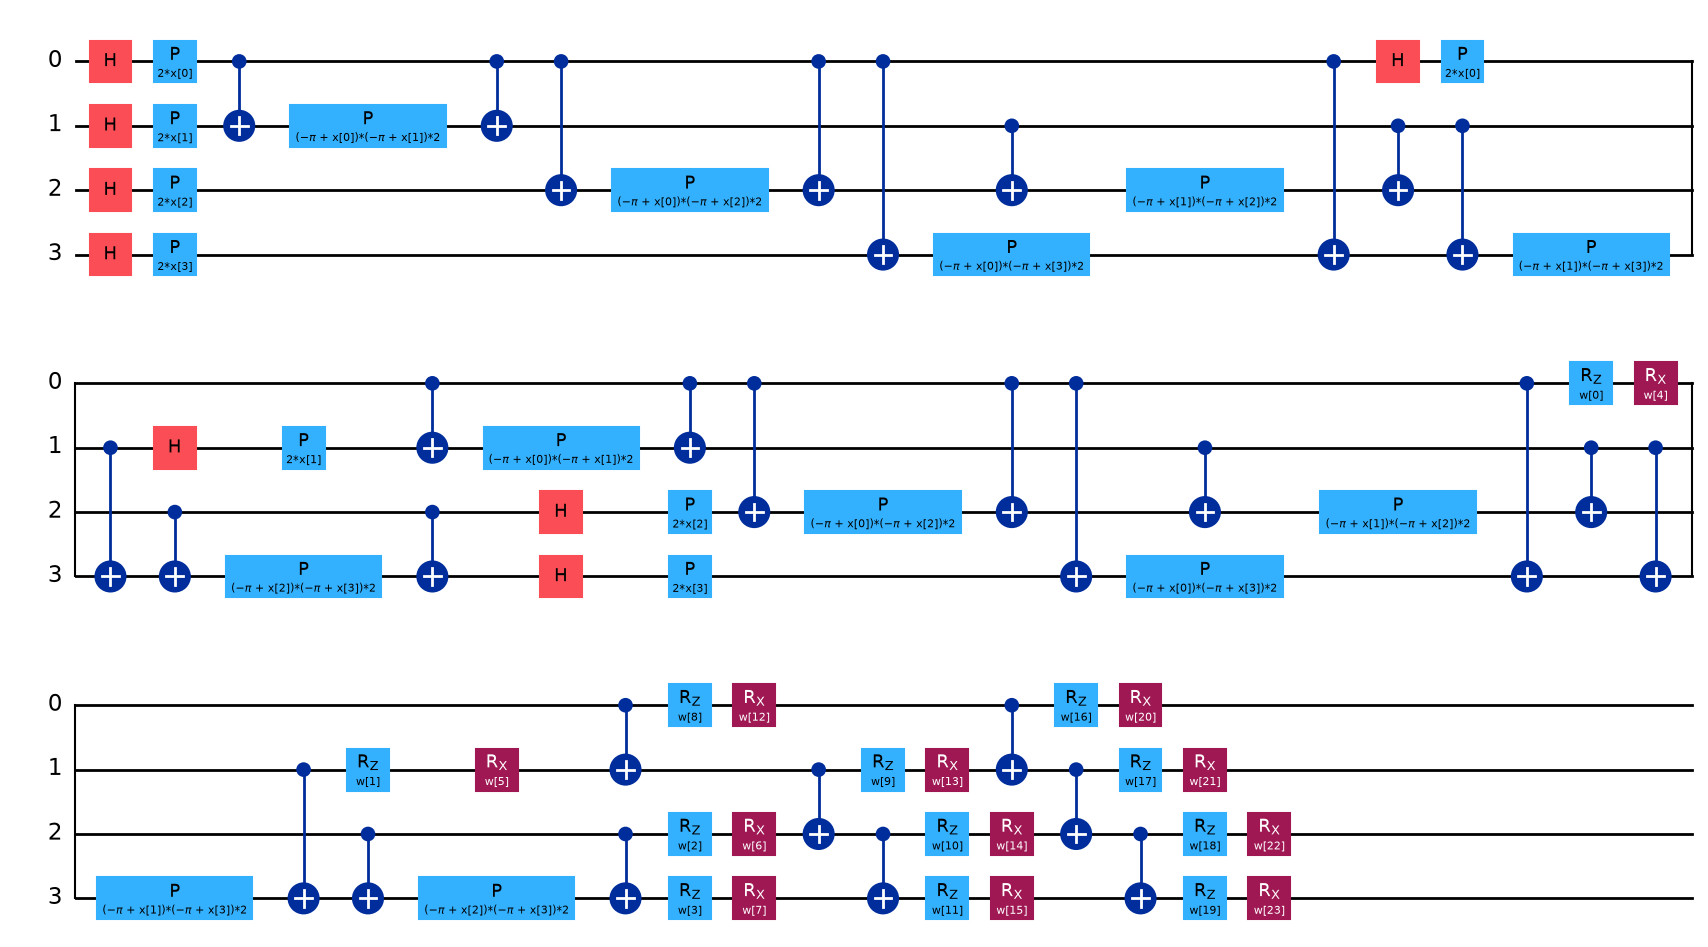

In [579]:
## Your code here
feature_map = zz_feature_map(feature_dimension=4, reps=2)
##

# We are using the same circuit to learn the measurement basis
ansatz = n_local(nb_features, ['rz', 'rx'], 'cx', 'linear', reps=2, parameter_prefix='w')

qc = feature_map.compose(ansatz)
qc.draw('mpl')

In [580]:
# !!! Let's use the original noisy backend here !!!
sampler = Sampler(mode=backend)

circuit_qnn = SamplerQNN(circuit=qc,
                         sampler=sampler,
                         input_params=feature_map.parameters,  ## Put the list of parameters here!
                         weight_params=ansatz.parameters, 
                         interpret=parity, 
                         output_shape=nb_classes)

In [581]:
# Instanciate the class used to train the quantum classifier
circuit_classifier = NeuralNetworkClassifier(neural_network=circuit_qnn,
                                             optimizer=optimizer,
                                             initial_point=initial_weights)

# Train the model
circuit_classifier.fit(x_train, y_train)

/Users/karp2601/Recherche/présentations/polytechnique_2026/.venv/lib/python3.12/site-packages/scipy/_external/pyprima/common/preproc.py:68: UserWarning: COBYLA: Invalid MAXFUN; it should be at least num_vars + 2; it is set to 26
  warn(f'{solver}: Invalid MAXFUN; it should be at least {min_maxfun_str}; it is set to {maxfun}')


In [582]:
# Compute model accuracy on the training and test datasets
train_acc = circuit_classifier.score(x_train, y_train)
test_acc = circuit_classifier.score(x_test, y_test)

print(f">\n> Accuracy on the training set: {train_acc}\n> Accuracy on the test set: {test_acc}\n>")

>
> Accuracy on the training set: 0.9875
> Accuracy on the test set: 1.0
>


You can also explore on your own, the effects of the following on your model's performance:
* different feature map or data embedding
* optimizer (number of iterations or switch optimizer for SPSA, for example)
* measurement interpretation function